In [23]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
df = sns.load_dataset("titanic")

# Preview the data
display(df.head())

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [24]:
df.shape

(891, 15)

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [26]:
df.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


In [27]:
df.duplicated().sum()

np.int64(107)

In [28]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [29]:
# Summary statistics for Age
print(df["age"].describe())

# Number and percentage of missing ages
missing_age = df["age"].isnull().sum()
missing_percent = df["age"].isnull().mean() * 100

print("Missing ages:", missing_age)
print(f"Missing age percentage: {missing_percent:.2f}%")

# Skewness
print("Age skewness:", df["age"].skew())

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: age, dtype: float64
Missing ages: 177
Missing age percentage: 19.87%
Age skewness: 0.38910778230082704


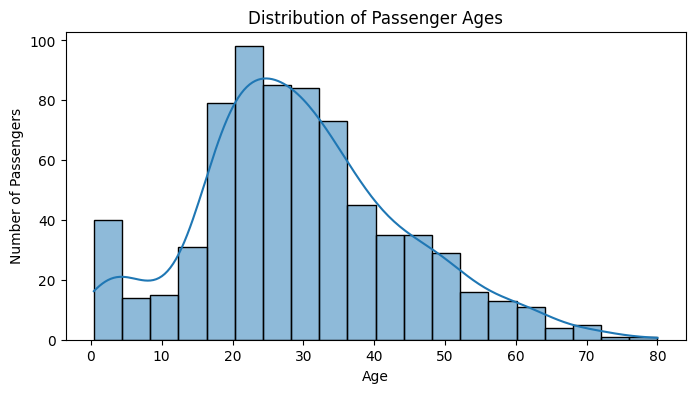

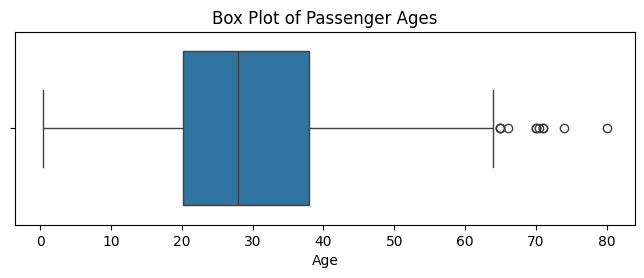

In [30]:
age_data = df["age"].dropna()


plt.figure(figsize=(8, 4))
sns.histplot(age_data, bins=20, kde=True)
plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()


plt.figure(figsize=(8, 2.5))
sns.boxplot(x=age_data)
plt.title("Box Plot of Passenger Ages")
plt.xlabel("Age")
plt.show()

In [31]:
Q1 = age_data.quantile(0.25)
Q3 = age_data.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = age_data[
    (age_data < lower_bound) |
    (age_data > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential outliers:", len(outliers))
print("Outlier ages:")
print(outliers.sort_values().to_list())

Q1: 20.125
Q3: 38.0
IQR: 17.875
Lower bound: -6.6875
Upper bound: 64.8125
Potential outliers: 11
Outlier ages:
[65.0, 65.0, 65.0, 66.0, 70.0, 70.0, 70.5, 71.0, 71.0, 74.0, 80.0]


Potential outlier ages:
[65.0, 65.0, 65.0, 66.0, 70.0, 70.0, 70.5, 71.0, 71.0, 74.0, 80.0]

Age statistics by survival:


,count,mean,median,min,max
survived,,,,,
0,424,30.626179,28.0,1.00,74.0
1,290,28.343690,28.0,0.42,80.0


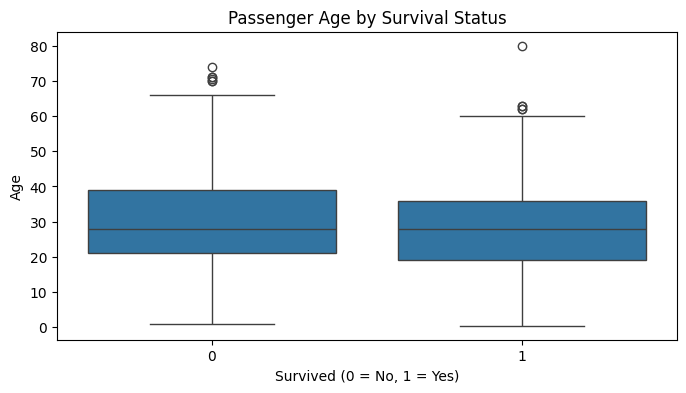

In [32]:
# Inspect potential outlier ages
print("Potential outlier ages:")
print(outliers.sort_values().to_list())

# Compare age statistics by survival status
print("\nAge statistics by survival:")
display(
    df.groupby("survived")["age"]
      .agg(["count", "mean", "median", "min", "max"])
)

# Compare the age distributions visually
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="survived", y="age")
plt.title("Passenger Age by Survival Status")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Age")
plt.show()

survived    0    1
pclass            
1          80  136
2          97   87
3         372  119

Survival rate by passenger class:
pclass
1    62.96
2    47.28
3    24.24
Name: survived, dtype: float64


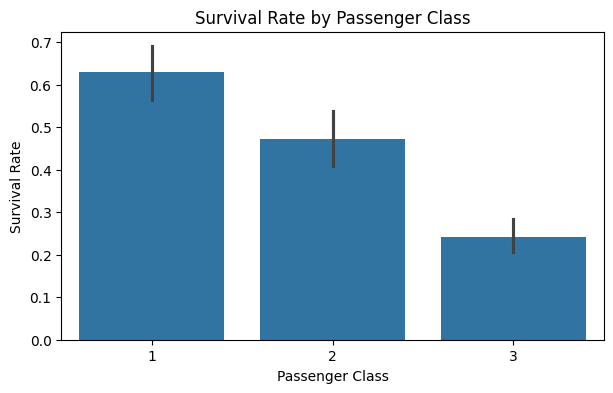

In [33]:

print(pd.crosstab(df["pclass"], df["survived"]))

survival_rate = (
    df.groupby("pclass")["survived"]
      .mean()
      .mul(100)
)

print("\nSurvival rate by passenger class:")
print(survival_rate.round(2))


plt.figure(figsize=(7, 4))
sns.barplot(data=df, x="pclass", y="survived")
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.show()

survived    0    1
sex               
female     81  233
male      468  109

survival rate by sex:
sex
female    74.20
male      18.89
Name: survived, dtype: float64


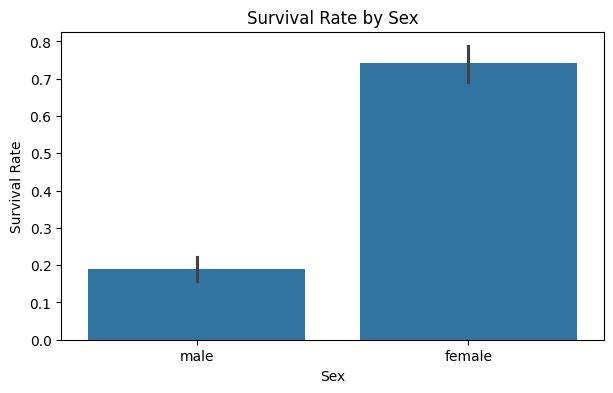

In [34]:
print(pd.crosstab(df["sex"], df["survived"]))

sex_survival = (
    df.groupby("sex")["survived"]
    .mean()
    .mul(100)
)
print("\nsurvival rate by sex:")
print(sex_survival.round(2))

plt.figure(figsize=(7,4))
sns.barplot(data=df,x="sex",y="survived")
plt.title("Survival Rate by Sex")
plt.xlabel("Sex")
plt.ylabel("Survival Rate")
plt.show()

In [35]:

survival_table = pd.crosstab(
    [df["pclass"], df["sex"]],
    df["survived"],
    normalize="index"
) * 100

survival_table.columns = ["Did not survive (%)", "Survived (%)"]

display(survival_table.round(2))

Did not survive (%)  Survived (%)
pclass sex                                      
1      female                 3.19         96.81
       male                  63.11         36.89
2      female                 7.89         92.11
       male                  84.26         15.74
3      female                50.00         50.00
       male                  86.46         13.54

In [36]:
summary = (
    df.groupby(["pclass", "sex"])["survived"]
      .agg(["count", "mean"])
      .rename(columns={
          "count": "passengers",
          "mean": "survival_rate"
      })
)

summary["survival_rate"] = (summary["survival_rate"] * 100).round(2)

display(summary)

passengers  survival_rate
pclass sex                              
1      female          94          96.81
       male           122          36.89
2      female          76          92.11
       male           108          15.74
3      female         144          50.00
       male           347          13.54

In [37]:
import numpy as np
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 12, 18, 35, 60, np.inf],
    labels=[
        "Child (0–12)",
        "Teen (13–18)",
        "Young adult (19–35)",
        "Adult (36–60)",
        "Older adult (60+)"
    ],
    include_lowest=True
)

age_survival = (
    df.groupby("age_group", observed=False)["survived"]
      .agg(["count", "mean"])
      .rename(columns={
          "count": "passengers",
          "mean": "survival_rate"
      })
)

age_survival["survival_rate"] *= 100

display(age_survival.round(2))

,passengers,survival_rate
age_group,,
Child (0–12),69,57.97
Teen (13–18),70,42.86
Young adult (19–35),358,38.27
Adult (36–60),195,40.00
Older adult (60+),22,22.73


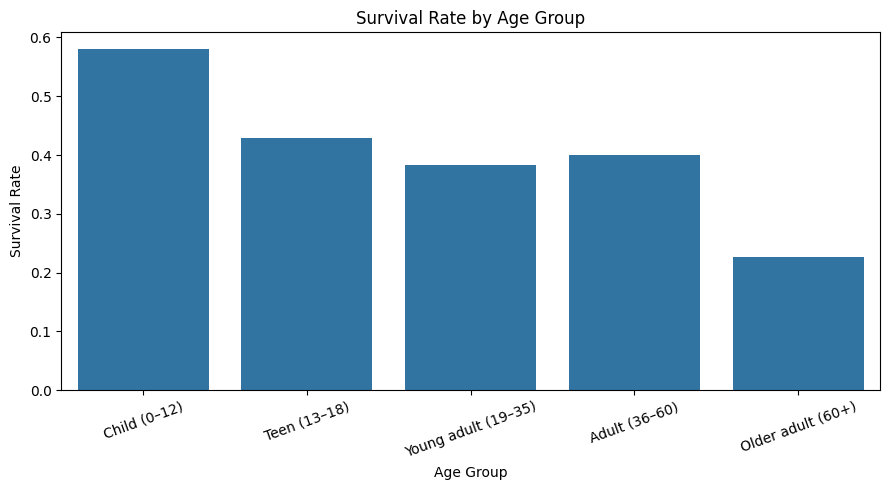

In [38]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="age_group",
    y="survived",
    order=[
        "Child (0–12)",
        "Teen (13–18)",
        "Young adult (19–35)",
        "Adult (36–60)",
        "Older adult (60+)"
    ],
    errorbar=None
)

plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()